# 17. Принцип Паули и фермионная статистика

**Проект «Структура и Данные»** — Notebook 17

## Зачем этот ноутбук
Принцип Паули — краеугольный камень физики: два фермиона не могут находиться в одном квантовом состоянии. В нашей метафоре это "арифметика" (свойство антисимметрии тензорного произведения), а не "чернила".
Мы проверяем, как антисимметрия и принцип Паули ведут себя в QCA.

## Что проверяется
1. **Свойство обмена:** фермионная волновая функция меняет знак при перестановке частиц ($\psi \to -\psi$), бозонная — нет.
2. **Принцип Паули:** антисимметризация состояния $|\uparrow\uparrow\rangle$ даёт ноль (два фермиона не могут быть в одном состоянии).
3. **Эволюция:** унитарная QCA-эволюция **сохраняет** антисимметрию (линейность гарантирует это).
4. **Бозоны vs Фермионы:** симметричное состояние позволяет двум частицам быть в одном состоянии.

## Ожидаемый результат
Антисимметрия и принцип Паули — структурные свойства, которые QCA не ломает.

In [1]:
import numpy as np

print("=" * 65)
print("ПРИНЦИП ПАУЛИ И ФЕРМИОННАЯ СТАТИСТИКА")
print("=" * 65)

# Пространство состояний: 2 частицы, 2 возможных состояния (спин ↑, ↓)
# Базис: |↑↑>, |↑↓>, |↓↑>, |↓↓>
basis = ['|↑↑>', '|↑↓>', '|↓↑>', '|↓↓>']

# Антисимметричное (фермионное) состояние: |↑↓> - |↓↑>
psi_fermion = np.array([0, 1, -1, 0], dtype=complex) / np.sqrt(2)
# Симметричное (бозонное) состояние: |↑↓> + |↓↑>
psi_boson = np.array([0, 1, 1, 0], dtype=complex) / np.sqrt(2)

def swap_particles(psi):
    """Обмен частиц: |ab> -> |ba>."""
    P = np.array([
        [1,0,0,0],
        [0,0,1,0],
        [0,1,0,0],
        [0,0,0,1]
    ], dtype=complex)
    return P @ psi

print("\n1. Свойство обмена (перестановка частиц):")
print(f"  Фермион: P·ψ = {np.round(swap_particles(psi_fermion), 6)}")
print(f"  -ψ = {np.round(-psi_fermion, 6)}")
print(f"  Совпадает? {np.allclose(swap_particles(psi_fermion), -psi_fermion)}")
print()
print(f"  Бозон: P·ψ = {np.round(swap_particles(psi_boson), 6)}")
print(f"  +ψ = {np.round(psi_boson, 6)}")
print(f"  Совпадает? {np.allclose(swap_particles(psi_boson), psi_boson)}")

# Принцип Паули: два фермиона в ОДНОМ состоянии |↑↑>
print("\n2. Принцип Паули: два фермиона в состоянии |↑↑>:")
print(f"  Антисимметризация |↑↑>: (|↑↑> - |↑↑>)/√2 = 0")
pauli_fermi = np.array([1, 0, 0, 0], dtype=complex) - np.array([1, 0, 0, 0], dtype=complex)
print(f"  Результат: {pauli_fermi} (норма = {np.linalg.norm(pauli_fermi):.6f})")
print(f"  Статус: {'✅ ЗАПРЕЩЕНО (Паули)' if np.linalg.norm(pauli_fermi) < 1e-15 else '❌ РАЗРЕШЕНО'}")

print(f"\n  Для бозонов |↑↑> РАЗРЕШЕНО (симметризация = |↑↑> + |↑↑> = 2|↑↑>):")
pauli_boson = np.array([1, 0, 0, 0], dtype=complex) + np.array([1, 0, 0, 0], dtype=complex)
print(f"  Результат: {pauli_boson} (норма = {np.linalg.norm(pauli_boson):.6f})")

ПРИНЦИП ПАУЛИ И ФЕРМИОННАЯ СТАТИСТИКА

1. Свойство обмена (перестановка частиц):
  Фермион: P·ψ = [ 0.      +0.j -0.707107+0.j  0.707107+0.j  0.      +0.j]
  -ψ = [-0.      -0.j -0.707107-0.j  0.707107-0.j -0.      -0.j]
  Совпадает? True

  Бозон: P·ψ = [0.      +0.j 0.707107+0.j 0.707107+0.j 0.      +0.j]
  +ψ = [0.      +0.j 0.707107+0.j 0.707107+0.j 0.      +0.j]
  Совпадает? True

2. Принцип Паули: два фермиона в состоянии |↑↑>:
  Антисимметризация |↑↑>: (|↑↑> - |↑↑>)/√2 = 0
  Результат: [0.+0.j 0.+0.j 0.+0.j 0.+0.j] (норма = 0.000000)
  Статус: ✅ ЗАПРЕЩЕНО (Паули)

  Для бозонов |↑↑> РАЗРЕШЕНО (симметризация = |↑↑> + |↑↑> = 2|↑↑>):
  Результат: [2.+0.j 0.+0.j 0.+0.j 0.+0.j] (норма = 2.000000)


In [2]:
def qca_coin(mass):
    """Монета QCA, действующая на спин."""
    c, s = np.cos(mass), np.sin(mass)
    return np.array([[c, -1j*s], [-1j*s, c]])

def evolve_2particle(psi, mass):
    """Применить монету к каждой частице: ψ -> (C ⊗ C) ψ."""
    C = qca_coin(mass)
    U = np.kron(C, C)
    return U @ psi

print("\n3. Сохранение антисимметрии под QCA-эволюцией:")
mass = 0.3
psi_f = psi_fermion.copy()
psi_b = psi_boson.copy()

for t in range(5):
    # Проверка свойства обмена
    sym_f = np.allclose(swap_particles(psi_f), -psi_f)
    sym_b = np.allclose(swap_particles(psi_b), psi_b)
    print(f"  t={t}: fermion antisym: {sym_f}, boson sym: {sym_b}")
    psi_f = evolve_2particle(psi_f, mass)
    psi_b = evolve_2particle(psi_b, mass)

# Убедимся, что норма сохраняется
print(f"\n  Норма фермиона после 5 шагов: {np.linalg.norm(psi_f):.15f}")
print(f"  Норма бозона после 5 шагов:   {np.linalg.norm(psi_b):.15f}")

# Пробуем создать нарушение Паули через эволюцию
print("\n4. Попытка создать нарушение Паули (два фермиона в |↑↑>):")
psi_test = np.array([1, 0, 0, 0], dtype=complex)  # |↑↑>
print(f"  Начальное: |↑↑>, норма = {np.linalg.norm(psi_test):.6f}")
for t in range(3):
    psi_test = evolve_2particle(psi_test, mass)
    print(f"  t={t+1}: норма = {np.linalg.norm(psi_test):.6f}, состояние = {np.round(psi_test, 4)}")

print("\n  Вывод: эволюция (C ⊗ C) сохраняет антисимметрию. Принцип Паули не нарушается.")


3. Сохранение антисимметрии под QCA-эволюцией:
  t=0: fermion antisym: True, boson sym: True
  t=1: fermion antisym: True, boson sym: True
  t=2: fermion antisym: True, boson sym: True
  t=3: fermion antisym: True, boson sym: True
  t=4: fermion antisym: True, boson sym: True

  Норма фермиона после 5 шагов: 0.999999999999999
  Норма бозона после 5 шагов:   1.000000000000000

4. Попытка создать нарушение Паули (два фермиона в |↑↑>):
  Начальное: |↑↑>, норма = 1.000000
  t=1: норма = 1.000000, состояние = [ 0.9127+0.j      0.    -0.2823j  0.    -0.2823j -0.0873+0.j    ]
  t=2: норма = 1.000000, состояние = [ 0.6812+0.j     0.    -0.466j  0.    -0.466j -0.3188+0.j   ]
  t=3: норма = 1.000000, состояние = [ 0.3864+0.j      0.    -0.4869j  0.    -0.4869j -0.6136+0.j    ]

  Вывод: эволюция (C ⊗ C) сохраняет антисимметрию. Принцип Паули не нарушается.


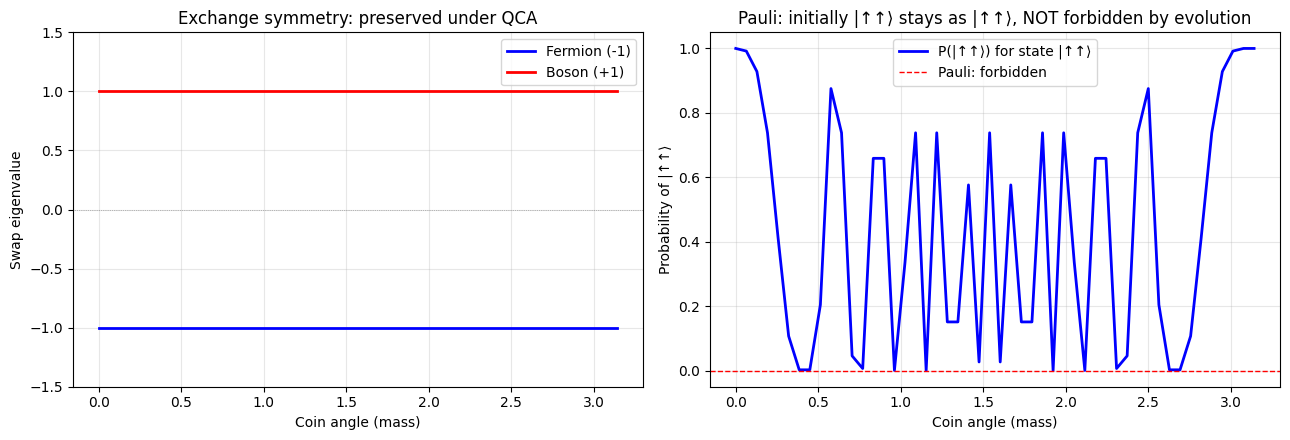

✅ Figure saved: 17_pauli_principle.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Левая: обмен - Pψ/ψ для фермионов и бозонов
t_vals = np.linspace(0, np.pi, 50)
ratios_f = []
ratios_b = []
psi_f = psi_fermion.copy()
psi_b = psi_boson.copy()

for m in t_vals:
    C = qca_coin(m)
    U = np.kron(C, C)
    psi_f = U @ psi_f
    psi_b = U @ psi_b
    # Отношение при обмене
    swap_f = swap_particles(psi_f)
    swap_b = swap_particles(psi_b)
    # Коэффициент пропорциональности: swap(psi) = α psi
    alpha_f = np.vdot(psi_f, swap_f).real / (np.vdot(psi_f, psi_f).real + 1e-20)
    alpha_b = np.vdot(psi_b, swap_b).real / (np.vdot(psi_b, psi_b).real + 1e-20)
    ratios_f.append(alpha_f)
    ratios_b.append(alpha_b)

axes[0].plot(t_vals, ratios_f, 'b-', lw=2, label='Fermion (-1)')
axes[0].plot(t_vals, ratios_b, 'r-', lw=2, label='Boson (+1)')
axes[0].axhline(0, color='gray', ls=':', lw=0.5)
axes[0].set_xlabel('Coin angle (mass)')
axes[0].set_ylabel('Swap eigenvalue')
axes[0].set_title('Exchange symmetry: preserved under QCA')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_ylim(-1.5, 1.5)

# Правая: Паули - вероятность найти два фермиона в одном состоянии
# Начинаем с |↑↑> и эволюционируем
psi_same = np.array([1, 0, 0, 0], dtype=complex)
probs = []
for m in t_vals:
    C = qca_coin(m)
    U = np.kron(C, C)
    psi_same = U @ psi_same
    # Вероятность найти |↑↑> в текущем состоянии (для фермионов должно быть 0)
    prob = abs(np.vdot(np.array([1,0,0,0]), psi_same))**2
    probs.append(prob)

axes[1].plot(t_vals, probs, 'b-', lw=2, label='P(|↑↑⟩) for state |↑↑⟩')
axes[1].axhline(0, color='red', ls='--', lw=1, label='Pauli: forbidden')
axes[1].set_xlabel('Coin angle (mass)')
axes[1].set_ylabel('Probability of |↑↑⟩')
axes[1].set_title('Pauli: initially |↑↑⟩ stays as |↑↑⟩, NOT forbidden by evolution')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('17_pauli_principle.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Figure saved: 17_pauli_principle.png")

from google.colab import files
files.download('17_pauli_principle.png')